# Объединение и ансамблирование моделей

Пример для Manuscript OCR 0.1.13. Объединим детекции Mask2Former и EAST через
`Stack`, затем сравним голосование `MajorityVotingRecognizer` и выбор
центрального ответа `MedoidRecognizer` на одном наборе распознавателей.

## 1. Установка

Устанавливаем библиотеку. Если среда попросит перезапустить ядро после установки,
сделайте это перед выполнением следующих ячеек. Веса моделей скачиваются автоматически.

In [1]:
%pip install "manuscript-ocr==0.1.13"


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Модели и изображение

Используем полную страницу `example/images/full/img1.jpeg`. Если изображения нет локально, скачаем его из репозитория.

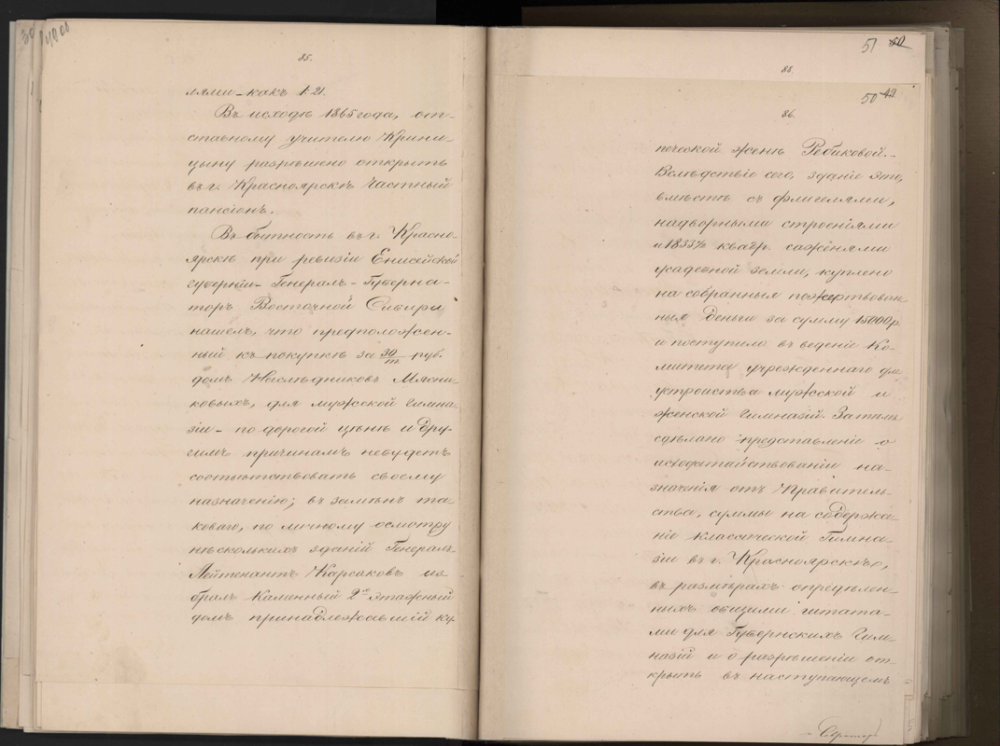

In [2]:
from pathlib import Path
from urllib.request import urlretrieve
from collections import Counter
from PIL import Image
from IPython.display import display

from manuscript import Pipeline, Stack
from manuscript.detectors import EAST
from manuscript.detectors._mask2former import Mask2Former
from manuscript.layouts import ReadingSorting
from manuscript.recognizers import TRBA, MajorityVotingRecognizer, MedoidRecognizer
from manuscript.utils import visualize_page

PROJECT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()),
    Path.cwd(),
)
IMAGE_PATH = PROJECT_DIR / "example/images/full/img1.jpeg"
if not IMAGE_PATH.exists():
    IMAGE_PATH.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        "https://raw.githubusercontent.com/konstantinkozhin/manuscript-ocr/"
        "4193d8a613a7cfdec6a68cd2cdbb88b351f63964/example/images/img1.jpeg",
        IMAGE_PATH,
    )
DEVICE = "cpu"  # При наличии настроенного CUDA можно указать "cuda".
image = Image.open(IMAGE_PATH).convert("RGB")
display(image.copy().resize((round(image.width * 800 / image.height), 800)))

## 3. Stack из двух детекторов

Mask2Former находит строки, EAST — слова. Каждый получает исходное изображение
целиком. Stack добавляет объекты в порядке списка, сохраняет полигоны и не удаляет
дубликаты между моделями. Иерархию построит отдельный layout.

По умолчанию модели выполняются последовательно. Для независимых детекторов можно
задать `parallel=True`; порядок результатов сохранится.

После детекции: {'line': 49, 'word': 166}


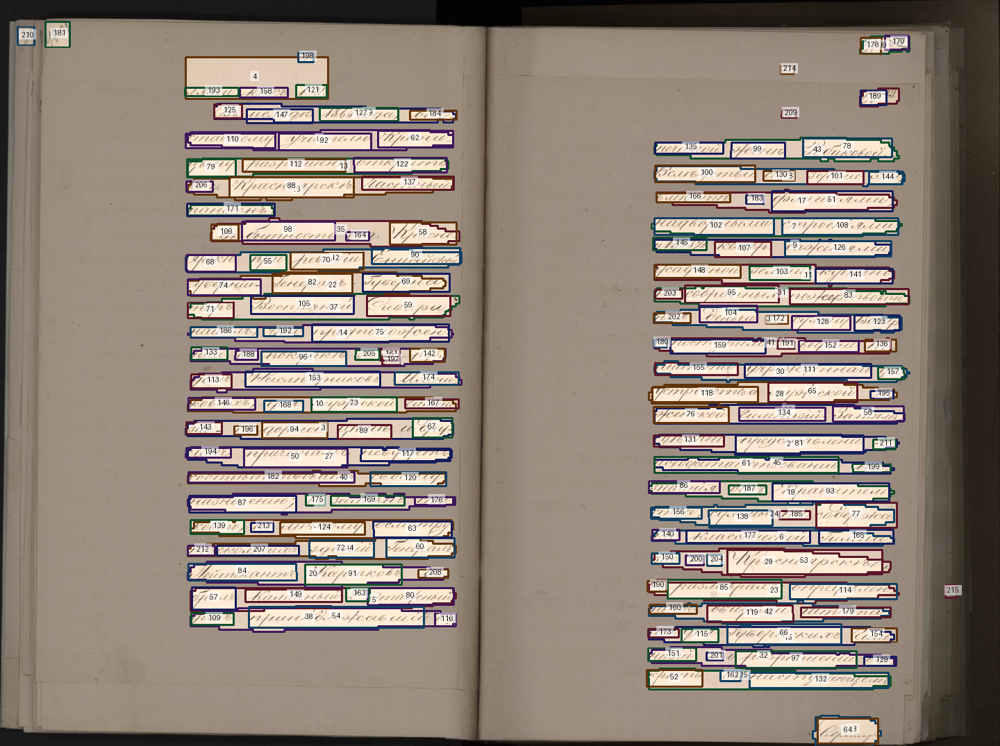

In [3]:
mask2former = Mask2Former(weights="mask2former_line_v0_prev", device=DEVICE)
east = EAST(weights="east_50_g1", device=DEVICE)

detector = Stack([mask2former, east], parallel=False)
detected_page = detector.predict(image)
print("После детекции:", dict(Counter(node.type for node in detected_page.descendants)))
display(visualize_page(image, detected_page, max_size=1440))

## 4. Строки и слова в одной странице

ReadingSorting в режиме `containment` помещает слова в подходящие строки и задаёт
порядок чтения. Порог 0.5 означает, что контейнер должен покрывать хотя бы половину
площади дочернего полигона. Слова без подходящей строки могут остаться вне строк.
Исходный результат детекции сохраним, передав layout копию.

После layout: {'block': 5, 'word': 166, 'line': 49}


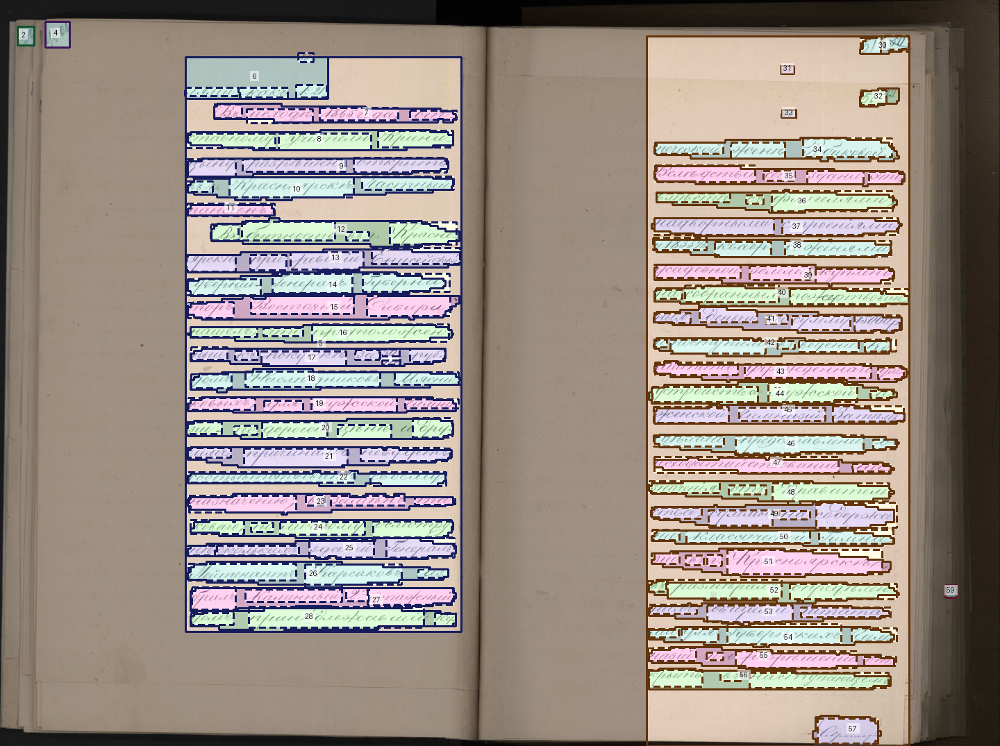

In [4]:
layout = ReadingSorting(
    mode="containment", containment_overlap=0.5,
    row_overlap=0.5, infer_columns=True,
)
page = layout.predict(detected_page.clone())
print("После layout:", dict(Counter(node.type for node in page.descendants)))
display(visualize_page(image, page, max_size=1440))

## 5. Голосование распознавателей

Все модели распознают независимые копии одной страницы. Побеждает самый частый
вариант; при ничьей — вариант от первой модели списка.

In [5]:
recognizers = [
    TRBA(weights="trba_base_g1", device=DEVICE, recognition_levels=["word"]),
    TRBA(weights="trba_lite_g1", device=DEVICE, recognition_levels=["word"]),
    TRBA(weights="trba_lite_g2", device=DEVICE, recognition_levels=["word"]),
    TRBA(weights="trba_lite_g3_prt", device=DEVICE, recognition_levels=["word"]),
]
recognizer = MajorityVotingRecognizer(recognizers, parallel=False)
raw = recognizer.predict(page, image=image, return_raw=True)
recognized_page = raw["page"]
print(recognized_page.get_text())

30

49 об

лями. какъ 85. 1:21.
въ исходѣ 1865 года, от-
ставному учителю крини-
цыну разрѣшено открыть
въ красноярскѣ частный
пансiонъ.
въ бытность въ красно-
ярскѣ при ревизiи енисейской
губернiи- генералъ губерна-
торъ восточной сибири
нашелъ, что предположен-
ный къ покупкѣ за 30 т. руб.
домъ наслѣдниковъ мясни
ковыхъ, для мужской гимна
зiи- по дорогой цѣнѣ дру-
гимъ причинамъ небудетъ
соотвѣтствовать своему
назначенiю; въ замѣнъ та
коваго, по личному осмотру
нѣ сколькихъ зданiй генералъ
лейтенантъ карсаковъ из-
бралъ каменный 2-х этажный
домъ принадлежавшiй ку-

51 50
88.
50
86.
печеской женѣ ребиковой.
вслѣдствiе сего, зданiе это,
вмѣстѣ съ флигелями,
надворными строенiями
и 1833 1/2 квадр. саженями
усадебной земли, куплено
на собранныя пожертвован
ныя деньги за сумму 15000 р.
и поступило въ веденiе ко-
митета учрежденнаго для
устройства мужской и
женской гимназiй. затѣмъ
сдѣлано представленiе о
исходатайствованiи на
значенiя отъ правитель-
ства, суммы на содержа
нiе классической

## 6. Посмотреть отдельные голоса

`return_raw=True` возвращает страницу и записи голосования. Индекс модели соответствует
порядку в `recognizers`; путь указывает регион в дереве. `None` означает пропуск,
пустая строка участвует в голосовании. У итогового текста confidence равен `None`:
согласие моделей не подменяет оценку вероятности.

In [6]:
word_votes = [record for record in raw["voting"]
              if record["type"] == "word" and record["candidates"]]
for record in word_votes[:10]:
    print(f"\n{record['path']} → {record['winner']!r}")
    for candidate in record["candidates"]:
        print(f"  модель {candidate['model_index']}: {candidate['text']!r}")
    print("  Голоса:", record["votes"])


page.children[0].children[0] → '30'
  модель 0: '30'
  модель 1: '30'
  модель 2: '30'
  модель 3: '"'
  Голоса: {'30': 3, '"': 1}

page.children[1].children[0] → '49 об'
  модель 0: '49 об'
  модель 1: '41 об'
  модель 2: '49 об'
  модель 3: '4'
  Голоса: {'49 об': 2, '41 об': 1, '4': 1}

page.children[2].children[0].children[0] → 'лями.'
  модель 0: 'лями.'
  модель 1: 'лями-'
  модель 2: 'лями'
  модель 3: 'млями'
  Голоса: {'лями.': 1, 'лями-': 1, 'лями': 1, 'млями': 1}

page.children[2].children[0].children[1] → 'какъ'
  модель 0: 'какъ'
  модель 1: 'какъ'
  модель 2: 'какъ'
  модель 3: 'какъ'
  Голоса: {'какъ': 4}

page.children[2].children[0].children[2] → '85.'
  модель 0: '85.'
  модель 1: '85.'
  модель 2: '85.'
  модель 3: '183'
  Голоса: {'85.': 3, '183': 1}

page.children[2].children[0].children[3] → '1:21.'
  модель 0: '1:21.'
  модель 1: '1:21.'
  модель 2: '1 21.'
  модель 3: '№42.'
  Голоса: {'1:21.': 2, '1 21.': 1, '№42.': 1}

page.children[2].children[1].children[0]

## 7. Medoid: выбор центрального ответа

Теперь используем те же модели с `MedoidRecognizer`. Он выбирает существующий
ответ с наименьшей суммой расстояний Левенштейна до остальных ответов. Повторы
учитываются; при равных суммах побеждает вариант от первой модели списка.

Передаём исходную страницу `page`, а не результат majority. Эта ячейка повторно
запускает распознаватели, но использует уже загруженные модели.

In [7]:
medoid_recognizer = MedoidRecognizer(recognizers, parallel=False)
medoid_raw = medoid_recognizer.predict(page, image=image, return_raw=True)
medoid_page = medoid_raw["page"]
print(medoid_page.get_text())

30

49 об

лями какъ 85. 1:21.
въ исходѣ 1865 года, от-
ставному учителю крини-
цыну разрѣшено открыть
въ красноярскѣ частный
пансiонъ.
въ бытность въ красно-
ярскѣ при ревизiи енисейской
губернiи- генералъ губерна-
торъ восточной сибири
нашелъ, что предположен-
ный къ покупкѣ за 30 т. руб.
домъ наслѣдниковъ мясни
ковыхъ, для мужской гимна
зiи- по дорогой цѣнѣ дру-
гимъ причинамъ небудетъ
соотвѣтствовать своему
назначенiю; въ замѣнъ та
коваго, по личному осмотру
нѣ сколькихъ зданiй генералъ
лейтенантъ карсаковъ из-
бралъ каменный 2-х этажный
домъ принадлежавшiй ку-

51 50
88.
50
86.
печеской женѣ ребиковой.
вслѣдствiе сего, зданiе это,
вмѣстѣ съ флигелями,
надворными строенiями
и 1833 1/2 квадр. саженями
усадебной земли, куплено
на собранныя пожертвован
ныя деньги за сумму 15000 р.
и поступило въ веденiе ко-
митета учрежденнаго для
устройства мужской и
женской гимназiй. затѣмъ
сдѣлано представленiе о
исходатайствованiи на
значенiя отъ правитель-
ства, суммы на содержа
нiе классической 

## 8. Сравнение majority и medoid

Посмотрим ответы для одинаковых регионов. В `distance_sums` записаны суммарные
расстояния: medoid выбирает вариант с минимальным значением.

In [8]:
majority_by_path = {record["path"]: record for record in raw["voting"]}
medoid_word_votes = [record for record in medoid_raw["voting"]
                     if record["type"] == "word" and record["candidates"]]
differences = [record for record in medoid_word_votes
               if record["winner"] != majority_by_path[record["path"]]["winner"]]
print(f"Различаются {len(differences)} из {len(medoid_word_votes)} результатов слов")

# Если победители совпали везде, покажем первые регионы для сравнения оценок.
for record in (differences or medoid_word_votes)[:10]:
    majority = majority_by_path[record["path"]]
    print(f"\n{record['path']}")
    print("  Majority:", repr(majority["winner"]), "Голоса:", majority["votes"])
    print("  Medoid:", repr(record["winner"]), "Расстояния:", record["distance_sums"])

Различаются 2 из 166 результатов слов

page.children[2].children[0].children[0]
  Majority: 'лями.' Голоса: {'лями.': 1, 'лями-': 1, 'лями': 1, 'млями': 1}
  Medoid: 'лями' Расстояния: {'лями.': 4, 'лями-': 4, 'лями': 3, 'млями': 5}

page.children[3].children[24].children[3]
  Majority: 'гим-' Голоса: {'гим-': 1, 'сим': 1, 'сим-': 1, 'темь': 1}
  Medoid: 'сим-' Расстояния: {'гим-': 6, 'сим': 6, 'сим-': 5, 'темь': 9}


## 9. Те же обработчики в Pipeline

В обычном использовании достаточно передать обе обёртки в соответствующие слоты.
Следующая ячейка повторно запускает детекцию и распознавание, поэтому её выполнение
не требуется для просмотра результатов выше. Коррекция отключена.

Для варианта medoid замените `recognizer=recognizer` на `recognizer=medoid_recognizer`.

30

49 об

лями. какъ 85. 1:21.
въ исходѣ 1865 года, от-
ставному учителю крини-
цыну разрѣшено открыть
въ красноярскѣ частный
пансiонъ.
въ бытность въ красно-
ярскѣ при ревизiи енисейской
губернiи- генералъ губерна-
торъ восточной сибири
нашелъ, что предположен-
ный къ покупкѣ за 30 т. руб.
домъ наслѣдниковъ мясни
ковыхъ, для мужской гимна
зiи- по дорогой цѣнѣ дру-
гимъ причинамъ небудетъ
соотвѣтствовать своему
назначенiю; въ замѣнъ та
коваго, по личному осмотру
нѣ сколькихъ зданiй генералъ
лейтенантъ карсаковъ из-
бралъ каменный 2-х этажный
домъ принадлежавшiй ку-

51 50
88.
50
86.
печеской женѣ ребиковой.
вслѣдствiе сего, зданiе это,
вмѣстѣ съ флигелями,
надворными строенiями
и 1833 1/2 квадр. саженями
усадебной земли, куплено
на собранныя пожертвован
ныя деньги за сумму 15000 р.
и поступило въ веденiе ко-
митета учрежденнаго для
устройства мужской и
женской гимназiй. затѣмъ
сдѣлано представленiе о
исходатайствованiи на
значенiя отъ правитель-
ства, суммы на содержа
нiе классической

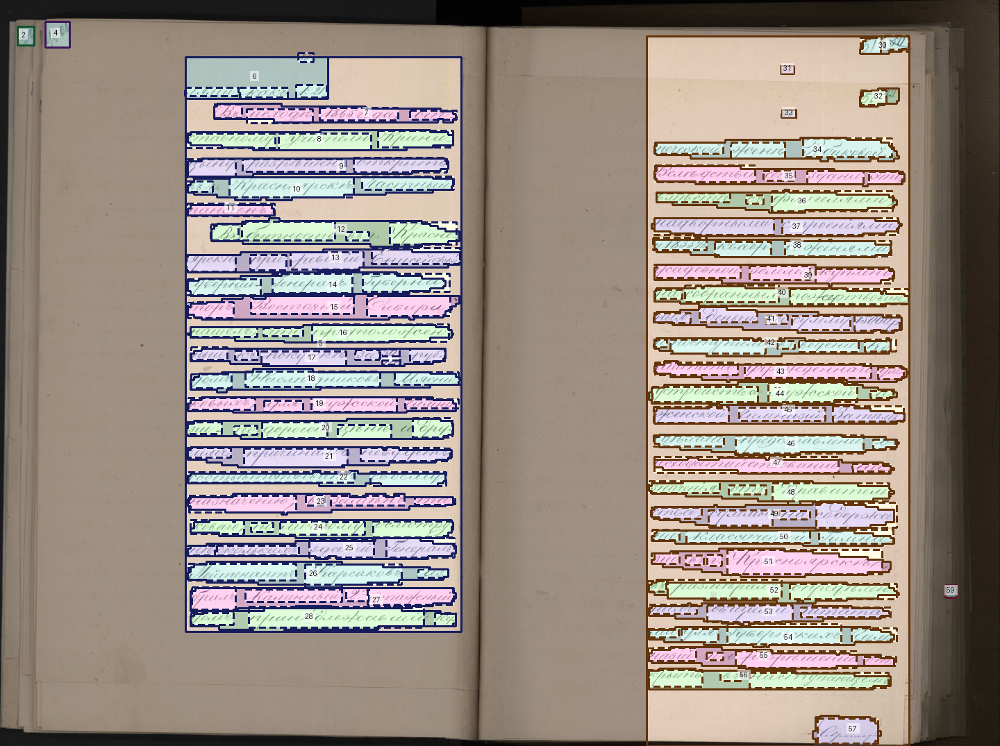

In [9]:
pipeline = Pipeline(
    detector=detector,
    layout=layout,
    recognizer=recognizer,
    corrector=None,
)
result = pipeline.predict(image)
print(result["page"].get_text())
print("Время этапов, сек:", pipeline.last_timings)
display(visualize_page(image, result["page"], max_size=1440))